# Lab 05: How to search documents by meaning

**CPU | API key: `OPENAI_API_KEY` for Parts A, D, E, F and G (Parts B and C run without one) | Follows: Day 1 D1-M07, steps 7.1 to 7.6 (D1-M07-01 to D1-M07-45, slides 210–250)**

## Goal

A rep who asks *when does the link stop working?* has no policy file name to give, so the copilot needs to find a
policy by what the question means. In this lab you build that search yourself: you compute cosine similarity by hand,
build an exact FAISS index of the support handbook, choose how to split the handbook, and test the search on
questions whose answer you know. The moment that teaches it: the search always returns three chunks with scores, and
the scores do not tell you whether any of them answers. *Do we take Bitcoin?*, which the payment policy answers,
scores about the same as *Do we match a lower price from another store?*, which no policy covers, and *Can a customer
pay in monthly instalments?*, which no policy covers either, scores higher than five of the twelve covered questions.
Nearest is not the same as relevant, and Lab 06 builds on that.

## What you will learn

- How to compute cosine similarity by hand, and why it is a plain dot product for OpenAI's embeddings.
- How to build, save and load an exact FAISS index (`IndexFlatIP`) and search it for the nearest chunks.
- How to choose a split for a handbook by checking where one rule lands and whether its chunk still names its file.
- How to predict the top file for a question, check the prediction, and explain a miss from what each chunk holds.
- Why a search score is not a probability, measured on questions the handbook covers and questions it does not.
- Optional: how keyword search (BM25) and reciprocal rank fusion work, and what hybrid search gains and loses, one
  question at a time.

| Part | What you do | Calls to OpenAI (embeddings only) |
|---|---|---|
| A | Cosine by hand on toy vectors, then on three embedded sentences | 1 |
| B | An exact FAISS index on toy vectors: raw, normalised, saved and loaded | 0 |
| C | Split the handbook by size and by heading; find where the duplicate-charge rule lands | 0 |
| D | Embed the 20 chunks, build, save and load the index, write `search`, and compare split A | 9 |
| E | Predict the top file for four rep questions, then search | 4 |
| F | Search for a question no policy covers, then test a score threshold on 18 labelled questions | 19 |
| G (optional) | BM25 by hand, then fuse it with the vector ranking | 12 |

This lab calls no chat model. Every call embeds text with `EMBED_MODEL`, under 10,000 tokens in all: about $0.0002
with `text-embedding-3-small`.

## The first two cells

These are the same two cells that open Lab 00, which explains each line. **Setup** finds the repository folder (on
Colab it copies the repository and installs the packages first). **Config** reads the model names from `models.env`
and finds your key without printing it.

In [1]:
# Setup: on Colab, copy the repository and install the packages. Locally (after uv sync) nothing is installed.
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("/content/agentic_ai_conversational_agents").exists():
        !git clone -q --depth 1 https://github.com/tatwan/agentic_ai_conversational_agents.git /content/agentic_ai_conversational_agents
    %cd /content/agentic_ai_conversational_agents
    %pip install -q -r requirements.txt

ROOT = next(folder for folder in [Path.cwd(), *Path.cwd().parents] if (folder / "models.env").exists())
sys.path.insert(0, str(ROOT))
print("Repository folder:", ROOT.name)

Repository folder: agentic_ai_conversational_agents


⚠️ On Colab, run the setup cell first in a fresh session. If another cell loaded the old `openai` package before the
install, the first model call fails with `ImportError: cannot import name ... from 'openai...'`; use **Runtime →
Restart session** and run from the top.

In [2]:
# Config: model names come from models.env; the key from the environment, .env or Colab Secrets.
from shared.settings import load_settings, load_key

settings = load_settings()
key_found_in = load_key("OPENAI_API_KEY")

for name in ("CHAT_MODEL", "REASONING_EFFORT", "JUDGE_MODEL", "EMBED_MODEL"):
    print(f"{name:18}{settings[name] or '(not set)'}")
print(f"{'OPENAI_API_KEY':18}{'found in ' + key_found_in if key_found_in else 'not found'}")

CHAT_MODEL        gpt-4o-mini
REASONING_EFFORT  (not set)
JUDGE_MODEL       gpt-4o-mini
EMBED_MODEL       text-embedding-3-small
OPENAI_API_KEY    found in .env


This lab uses only `EMBED_MODEL`. The picture shows what you will build: the top half runs once, whenever the
handbook changes; the bottom half runs for every question. Notice the last box: the search returns three chunks
whether or not any of them answers.

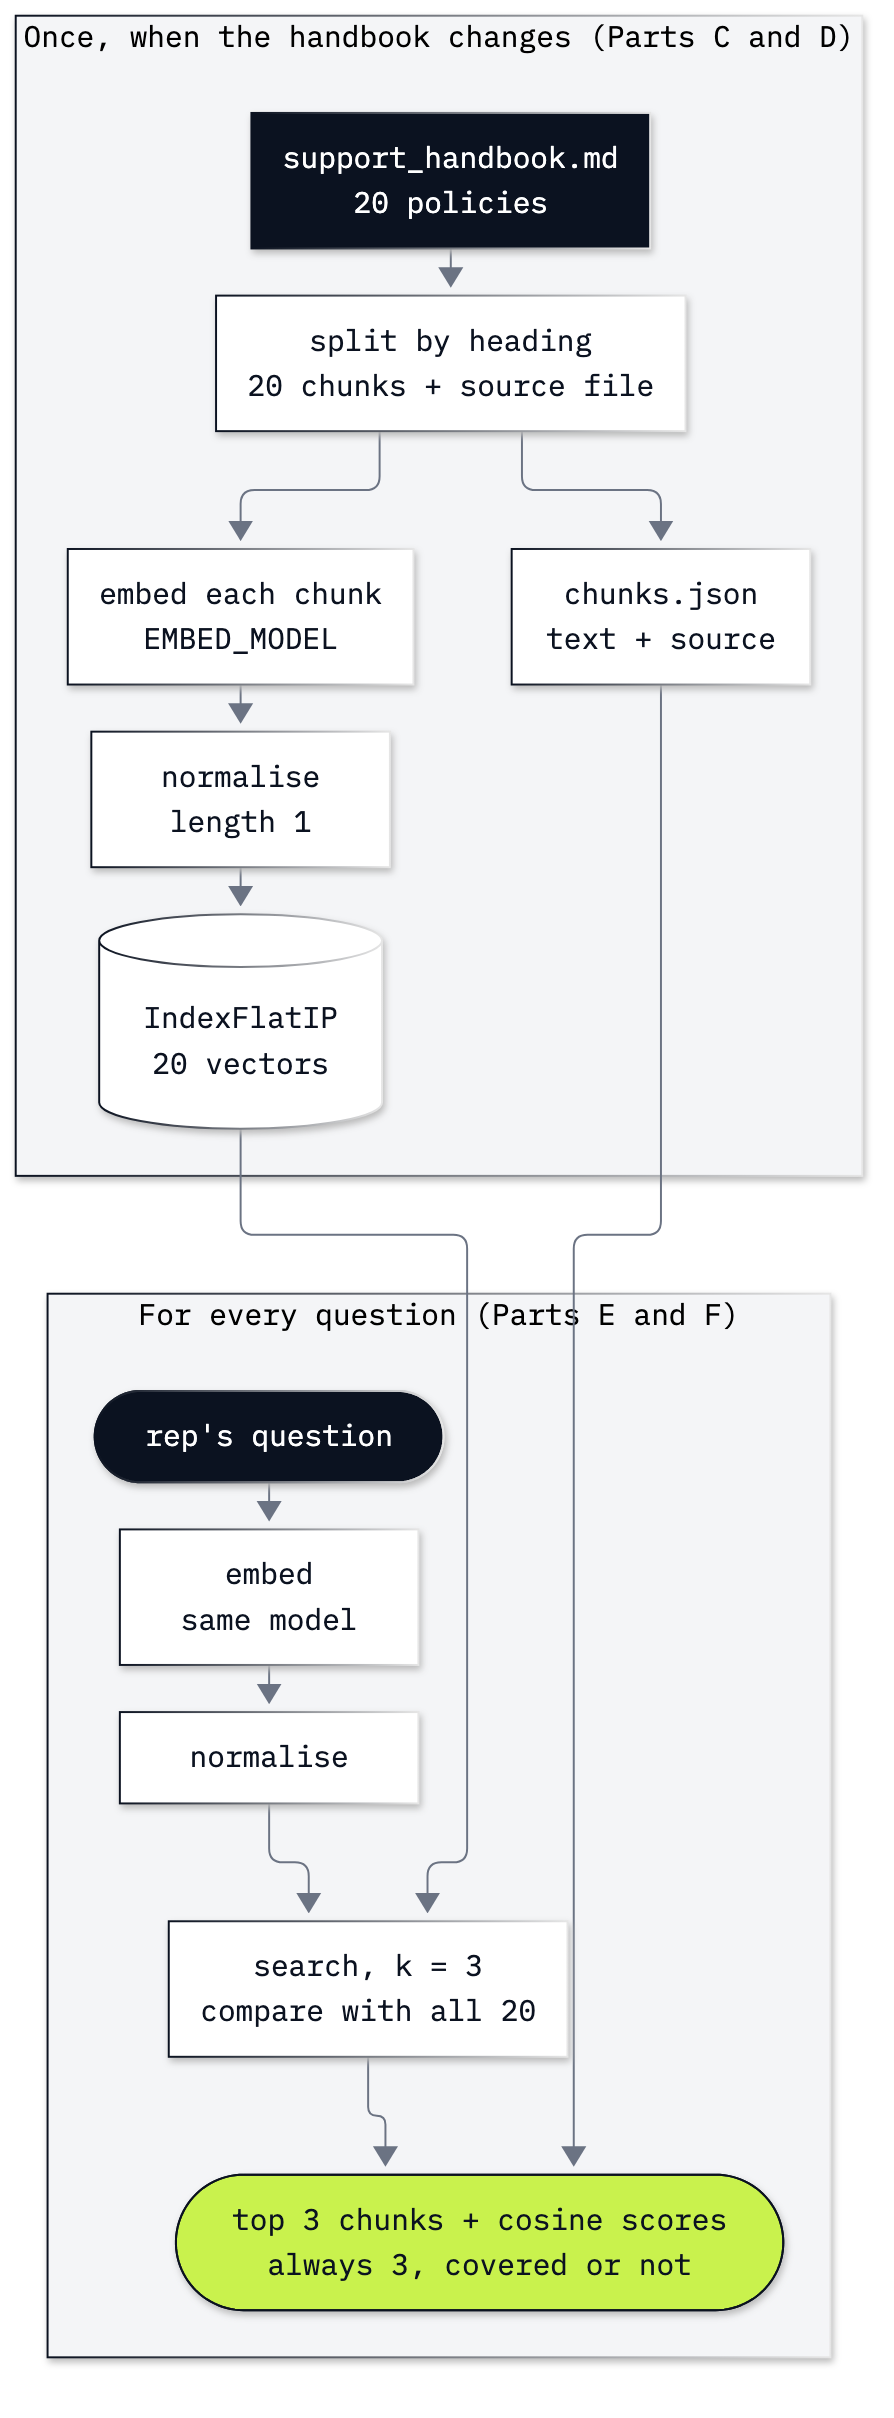

In [3]:
from IPython.display import Image
LAB = ROOT / "05_FAISS_Index_Handbook"
Image(filename=LAB / "resources" / "lab05_index_and_search.png", width=420)

---

## Part A: Measure closeness with cosine similarity

Part A gives you the measure every later part relies on: a number that says how close two texts are in meaning.

An **embedding** is a list of numbers that stands for a text, computed by an embedding model so that texts with
similar meanings get lists that point in similar directions. Each list is a **vector**. To compare two vectors we
use **cosine similarity**: multiply matching numbers and add them up (the **dot product**), then divide by the two
lengths. The result is 1 when the vectors point the same way, 0 when they are unrelated and -1 when they are
opposite. Length does not count, only direction.

Start with vectors of two numbers, small enough to check on paper: a question `q` and two documents `A` and `B`.

In [4]:
import numpy as np

q = np.array([1.0, 1.0])
A = np.array([1.0, 1.0])
B = np.array([5.0, 0.0])
print("dot(q, A) =", q @ A)
print("dot(q, B) =", q @ B)

dot(q, A) = 2.0
dot(q, B) = 5.0


`@` is the dot product. B has the bigger dot product, 5 against 2, only because B is long. Print the lengths.

In [5]:
for name, vector in [("q", q), ("A", A), ("B", B)]:
    print(name, "length", round(float(np.linalg.norm(vector)), 3))

q length 1.414
A length 1.414
B length 5.0


Divide the dot product by both lengths and the effect of length is gone.

In [6]:
def cosine(a, b):
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))

print("cosine(q, A) =", round(cosine(q, A), 4))
print("cosine(q, B) =", round(cosine(q, B), 4))

cosine(q, A) = 1.0
cosine(q, B) = 0.7071


A points exactly the way `q` points (1.0); B is 45 degrees away (0.7071). By cosine, A is the closer document,
the opposite of the dot product's order.

Now real text. The three sentences below are rep questions. Before you run the next cell, write down which pair
you expect to be closest and which pair furthest apart.

In [7]:
from shared.settings import embeddings

emb = embeddings(settings)          # EMBED_MODEL from models.env
SENTENCES = [
    "How long does a download link last?",
    "When does the link to download an album expire?",
    "Do we ship vinyl records to Chile?",
]
vectors = np.array(emb.embed_documents(SENTENCES))
print("shape:", vectors.shape)
print("first five numbers of sentence 1:", np.round(vectors[0][:5], 4))

shape: (3, 1536)
first five numbers of sentence 1: [-0.0159 -0.0173 -0.0231  0.0014 -0.0246]


`embeddings()` returns LangChain's `OpenAIEmbeddings` with the model named from `models.env`. Always name the model:
the class's own default is the older `text-embedding-ada-002`. `embed_documents` sent the three sentences in one call
and returned one vector per sentence. Each vector has 1,536 numbers, a length fixed by the model; the numbers on their
own mean nothing to a person.

Look at the length of each vector before computing any cosine.

In [8]:
print("lengths:", np.round(np.linalg.norm(vectors, axis=1), 4))

lengths: [1.     0.9999 1.0002]


Every length is 1 to about three decimals: OpenAI returns its embeddings already **normalised** to length 1
([OpenAI embeddings guide](https://developers.openai.com/api/docs/guides/embeddings), FAQ "Which distance function
should I use?"). For vectors of length 1 the division in `cosine` divides by 1, so the dot product alone is the
cosine. The next cell prints both.

In [9]:
pairs = [(0, 1), (0, 2), (1, 2)]
for i, j in pairs:
    print(f"sentences {i + 1} and {j + 1}: cosine {cosine(vectors[i], vectors[j]):.4f}   dot {vectors[i] @ vectors[j]:.4f}")

sentences 1 and 2: cosine 0.7059   dot 0.7058
sentences 1 and 3: cosine 0.1140   dot 0.1140
sentences 2 and 3: cosine 0.2407   dot 0.2407


When we ran it (`text-embedding-3-small`, 11 Oct 2026), sentences 1 and 2 scored 0.7059, sentences 2 and 3
0.2407, and sentences 1 and 3 0.1140, and the dot product agreed with the cosine to the third decimal. Sentences 1 and 2 share
only *does*, *download* and *link*, yet they ask the same thing, and they score far above the pair that asks
about shipping. Notice what the numbers are not: 0.71 does not mean "71 percent the same". Scores depend on the model,
and a different embedding model gives different values for the same pair.

### Checkpoint A

| You should see | Value from our run (11 Oct 2026, `text-embedding-3-small`) |
|---|---|
| Toy vectors | dot product: B 5.0, A 2.0; cosine: A 1.0, B 0.7071 |
| Shape | `(3, 1536)` |
| Lengths | 1.0 to about three decimals |
| Cosines | 1–2 0.7059, 2–3 0.2407, 1–3 0.1140; yours should agree to about the third decimal |

---

## Part B: Build an exact index with FAISS

Part B builds the structure that holds the vectors and finds the nearest ones, first on the toy vectors, where you
can check every number.

A **vector index** stores vectors so that, given a query vector, it returns the stored vectors nearest to it.
[FAISS](https://github.com/facebookresearch/faiss) (from Meta, `faiss-cpu` 1.15.1 here) is a library that does this
in memory on your machine. Its simplest index, `IndexFlatIP`, compares the query with every stored vector by
**inner product** (another name for the dot product) and returns the highest. Comparing with every vector makes it
**exact**: no stored vector is skipped.

Add A and B as they are, and search with `q`.

In [10]:
import faiss

docs = np.array([[1, 1], [5, 0]], dtype="float32")   # A, B
query = np.array([[1, 1]], dtype="float32")          # q
names = ["A", "B"]

raw = faiss.IndexFlatIP(2)        # 2 numbers per vector
raw.add(docs)
scores, ids = raw.search(query, 2)
print("scores:", scores)
print("row numbers:", ids)

scores: [[5. 2.]]
row numbers: [[1 0]]


`search` returns two arrays, one row per query: the scores, best first, and the **row numbers** of the matching
vectors, in the order they were added. FAISS keeps no names and no text; the row number is how you find your own
data again. Turn the rows into names.

In [11]:
print("raw inner product:", [(names[i], float(s)) for s, i in zip(scores[0], ids[0])])

raw inner product: [('B', 5.0), ('A', 2.0)]


On raw vectors the inner product ranks B first, because B is long: the dot product's order from Part A. To make the
index rank by cosine, give every vector length 1 first, the documents and the query. `faiss.normalize_L2` does that
in place, so work on copies.

In [12]:
unit_docs = docs.copy()
unit_query = query.copy()
faiss.normalize_L2(unit_docs)
faiss.normalize_L2(unit_query)

index = faiss.IndexFlatIP(2)
index.add(unit_docs)
scores, ids = index.search(unit_query, 2)
print("after normalize_L2:", [(names[i], round(float(s), 4)) for s, i in zip(scores[0], ids[0])])
print("cosine by numpy:   ", [(name, round(cosine(q, v), 4)) for name, v in [("A", A), ("B", B)]])

after normalize_L2: [('A', 1.0), ('B', 0.7071)]
cosine by numpy:    [('A', 1.0), ('B', 0.7071)]


After normalising, the inner product is the cosine: A 1.0, B 0.7071, the same as the numpy function. On unit vectors
`IndexFlatIP` is a cosine search.

Now check what `normalize_L2` does to real OpenAI vectors, which are already length 1.

In [13]:
real = vectors.astype("float32")
before = real.copy()
faiss.normalize_L2(real)
print("largest change to any number:", float(np.abs(real - before).max()))

largest change to any number: 1.4699995517730713e-05


When we ran it, the largest change was 0.000015: nothing that could change an order. For this model normalising
is a safety step, not a fix. Keep it anyway. If `EMBED_MODEL` changes to a model whose vectors are not length 1, the
same code still ranks by cosine, and the toy vectors above show what happens without it.

An index lives in memory. `faiss.write_index` saves it to a file and `faiss.read_index` loads it back. Save the toy
index in a temporary folder, read it back and search again.

In [14]:
import tempfile

toy_file = Path(tempfile.gettempdir()) / "lab05_toy.faiss"
faiss.write_index(index, str(toy_file))
loaded = faiss.read_index(str(toy_file))
again, again_ids = loaded.search(unit_query, 2)
print(type(loaded).__name__, "ntotal", loaded.ntotal, "d", loaded.d)
print("same results after reload:", bool((again == scores).all() and (again_ids == ids).all()))

IndexFlatIP ntotal 2 d 2
same results after reload: True


`ntotal` is the number of stored vectors and `d` the numbers per vector. The file holds the vectors and nothing else:
no text, no names. ⚠️ `read_index` trusts the file it reads, and the
[FAISS wiki](https://github.com/facebookresearch/faiss/wiki/Index-IO,-cloning-and-hyper-parameter-tuning) warns
that a crafted index file can run code on your machine. Load only index files you wrote, or that come with a repository you trust.

**Exact search is a fundamental here.** `IndexFlatIP` compares the query with every vector, which is right for 20
chunks and fine for many thousands. For millions of vectors FAISS offers approximate indexes such as HNSW (a graph of
neighbours) and IVF (a few clusters searched), which skip most vectors to answer fast
([FAISS wiki: guidelines to choose an index](https://github.com/facebookresearch/faiss/wiki/Guidelines-to-choose-an-index)).
In production, teams usually keep vectors in a vector database (Qdrant, Chroma, pgvector) or a hosted store such as
OpenAI's file search, which also handle saving, filtering and keyword search. Inside each of them is the same idea
you just ran.

### Checkpoint B

| You should see | Value from our run (11 Oct 2026) |
|---|---|
| Raw inner product | `[('B', 5.0), ('A', 2.0)]` |
| After `normalize_L2` | `[('A', 1.0), ('B', 0.7071)]`, the same as cosine in numpy |
| Real OpenAI vectors | largest change from normalising 0.000015 |
| Reload | `IndexFlatIP ntotal 2 d 2`, same results `True` |

---

## Part C: Split the handbook two ways

Part C decides what one stored vector stands for. The search can only return what you stored, so the way you cut
the handbook decides whether a rule can be found whole, with the file a citation needs.

A **chunk** is one piece of one document, embedded and returned as a unit. Too big, and one vector mixes several
topics; too small, and a rule loses the sentence that explains it. Each of the 36 files in `data/corpus/` is short
enough to be one chunk. The handbook joins the 20 policies into one document, so it must be split. Look at its shape.

In [15]:
from shared.copilot import HANDBOOK

text = HANDBOOK.read_text(encoding="utf-8")
print(len(text), "characters,", text.count("\n## "), "policy headings")
start = text.index("## Refunds")
print(text[start:text.index("## Returns")])

7428 characters, 20 policy headings
## Refunds
Source: policy_refunds.md

Refunds go back to the original payment method. They take 5 to 10 business days after support approves the request.

Partial refunds are allowed when only some tracks on a multi-disc set are defective.

We do not refund because a customer changed their mind about a digital purchase.

Duplicate charges: if two invoices exist for the same album on the same day, refund the later invoice in full. Attach both invoice numbers.




Every policy sits under a `##` heading, followed by a `Source:` line with its file name. The last line of the refunds
policy is the rule this part follows: *Duplicate charges: if two invoices exist for the same album on the same day,
refund the later invoice in full.*

**Split A, by size.** `RecursiveCharacterTextSplitter` is where LangChain's documentation tells you to start
([text splitters](https://docs.langchain.com/oss/python/integrations/splitters)): it cuts at blank lines, then at line
breaks, then at spaces, until every piece fits `chunk_size` characters. **Overlap** repeats the end of one chunk at
the start of the next, so a sentence cut at a boundary still appears whole in one of them; it is counted in
characters too. Use 1,000 characters with 200 of overlap, settings common in tutorials.

In [16]:
import statistics
from langchain_text_splitters import RecursiveCharacterTextSplitter

splitter_a = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200)
split_a = splitter_a.split_text(text)
sizes_a = [len(chunk) for chunk in split_a]
print(len(split_a), "chunks; characters min", min(sizes_a), "median", statistics.median(sizes_a), "max", max(sizes_a))
print("characters repeated through overlap:", sum(sizes_a) - len(text))

10 chunks; characters min 289 median 945.5 max 991
characters repeated through overlap: 1443


Ten chunks of up to 1,000 characters, and 1,443 characters stored twice. Now find the rule. The next cell prints, for
every chunk, whether it holds the whole rule, which policy headings it contains and which `Source:` lines.

In [17]:
import re

RULE = "Duplicate charges: if two invoices exist for the same album on the same day, refund the later invoice in full."

def describe(chunk_texts):
    for number, chunk in enumerate(chunk_texts):
        headings = re.findall(r"^## (.+)$", chunk, flags=re.MULTILINE)
        sources = re.findall(r"Source: (\S+)", chunk)
        print(f"chunk {number}: {len(chunk):4} chars | rule whole: {RULE in chunk!s:5} | headings {headings} | sources {sources}")

describe(split_a)

chunk 0:  955 chars | rule whole: False | headings ['Accounts', 'Cancellations', 'Damaged media'] | sources ['policy_accounts.md', 'policy_cancellations.md', 'policy_damaged_media.md']
chunk 1:  903 chars | rule whole: False | headings ['Damaged media', 'Data retention', 'Digital downloads'] | sources ['policy_damaged_media.md', 'policy_data_retention.md', 'policy_digital_downloads.md']
chunk 2:  988 chars | rule whole: False | headings ['Escalations', 'Exchanges'] | sources ['policy_escalations.md', 'policy_exchanges.md']
chunk 3:  988 chars | rule whole: False | headings ['Gift cards', 'International orders'] | sources ['policy_gift_cards.md', 'policy_international.md']
chunk 4:  923 chars | rule whole: False | headings ['Library and playlists', 'Payment', 'Preorders'] | sources ['policy_library.md', 'policy_payment.md', 'policy_preorders.md']
chunk 5:  991 chars | rule whole: False | headings ['Preorders', 'Privacy', 'Refunds'] | sources ['policy_preorders.md', 'policy_privacy.md', 

Python counts from 0, so chunk 6 is the seventh chunk. It holds the whole rule, but its headings are Returns and
Shipping and its only `Source:` lines are `policy_returns.md` and `policy_shipping.md`. The refunds heading and its
file are in chunk 5. Print where the splitter cut: the end of chunk 5 and the start of chunk 6.

In [18]:
print(split_a[5][-330:])
print("\n----- chunk 6 starts -----\n")
print(split_a[6][:420])

ion.md.

## Refunds
Source: policy_refunds.md

Refunds go back to the original payment method. They take 5 to 10 business days after support approves the request.

Partial refunds are allowed when only some tracks on a multi-disc set are defective.

We do not refund because a customer changed their mind about a digital purchase.

----- chunk 6 starts -----

Partial refunds are allowed when only some tracks on a multi-disc set are defective.

We do not refund because a customer changed their mind about a digital purchase.

Duplicate charges: if two invoices exist for the same album on the same day, refund the later invoice in full. Attach both invoice numbers.

## Returns
Source: policy_returns.md

Physical items (CDs, vinyl, boxed sets) may be returned within 30 days of


The overlap repeated two refund sentences, but the heading and the rule still landed in different chunks. A search
can return chunk 6 for a duplicate-charge question, and a copilot that cites the chunk's `Source:` line would cite
`policy_returns.md` for a refunds rule. Part D measures this.

**Split B, by heading.** Structured documents can be split on their structure: LangChain's
`MarkdownHeaderTextSplitter` starts a chunk at each heading you name and records the heading as metadata
([split markdown](https://docs.langchain.com/oss/python/integrations/splitters/markdown_header_metadata_splitter)).
`strip_headers=False` keeps the heading line in the chunk text, so the embedding sees it too.

In [19]:
from langchain_text_splitters import MarkdownHeaderTextSplitter

splitter_b = MarkdownHeaderTextSplitter(headers_to_split_on=[("##", "policy")], strip_headers=False)
docs_b = splitter_b.split_text(text)
print(len(docs_b), "pieces")
print("piece 0 metadata:", docs_b[0].metadata)
print("piece 1 metadata:", docs_b[1].metadata)
print(docs_b[1].page_content)

21 pieces
piece 0 metadata: {}
piece 1 metadata: {'policy': 'Accounts'}
## Accounts
Source: policy_accounts.md  
An account is the email plus the customer record. One email, one account.  
A customer can change their email once per calendar year. Invoices already issued keep the old email as a snapshot.  
Account deletion: we remove the login and the marketing flag. Invoices stay. Support tickets stay for 24 months, then they are dropped. See policy_data_retention.md.


21 pieces: the handbook's title paragraph (no `policy` in its metadata) and one per policy. Keep the 20 policies, and
for each, its text, its policy name and the file from its `Source:` line. That file is what a citation will name.

In [20]:
chunks = []
for doc in docs_b:
    if "policy" in doc.metadata:                      # skip the title paragraph
        source = doc.page_content.split("Source: ")[1].split()[0]
        chunks.append({"text": doc.page_content, "source": source, "policy": doc.metadata["policy"]})

sizes_b = [len(chunk["text"]) for chunk in chunks]
print(len(chunks), "chunks; characters min", min(sizes_b), "median", statistics.median(sizes_b), "max", max(sizes_b))
describe([chunk["text"] for chunk in chunks])

20 chunks; characters min 277 median 345.0 max 493
chunk 0:  400 chars | rule whole: False | headings ['Accounts'] | sources ['policy_accounts.md']
chunk 1:  340 chars | rule whole: False | headings ['Cancellations'] | sources ['policy_cancellations.md']
chunk 2:  315 chars | rule whole: False | headings ['Damaged media'] | sources ['policy_damaged_media.md']
chunk 3:  301 chars | rule whole: False | headings ['Data retention'] | sources ['policy_data_retention.md']
chunk 4:  437 chars | rule whole: False | headings ['Digital downloads'] | sources ['policy_digital_downloads.md']
chunk 5:  376 chars | rule whole: False | headings ['Escalations'] | sources ['policy_escalations.md']
chunk 6:  340 chars | rule whole: False | headings ['Exchanges'] | sources ['policy_exchanges.md']
chunk 7:  283 chars | rule whole: False | headings ['Gift cards'] | sources ['policy_gift_cards.md']
chunk 8:  412 chars | rule whole: False | headings ['International orders'] | sources ['policy_international.md

Twenty chunks of 277 to 493 characters. The rule is whole in chunk 13 (the fourteenth), alone with the rest of the
refunds policy, and the chunk names `policy_refunds.md`.

| Split | Chunks | Characters: min, median, max | Rule whole in | Names its own file? |
|---|---|---|---|---|
| A, by size | 10 | 289, 945.5, 991 | chunk 6, with Returns and Shipping | no: `policy_returns.md`, `policy_shipping.md` |
| B, by heading | 20 | 277, 345, 493 | chunk 13, refunds only | yes: `policy_refunds.md` |

Split B wins for this handbook because each policy is short and has a heading. A long policy would need both: split
by heading first, then by size inside each section, keeping the heading's metadata (Challenge 2).

Now collect the steps into one function, the one Lab 06 and later labs import from `shared/copilot.py`, and check
that yours gives the same chunks.

In [21]:
def split_handbook_mine(handbook=HANDBOOK):
    """Heading-aware split: one chunk per policy, with its policy name and source file."""
    splitter = MarkdownHeaderTextSplitter(headers_to_split_on=[("##", "policy")], strip_headers=False)
    result = []
    for doc in splitter.split_text(handbook.read_text(encoding="utf-8")):
        if "policy" in doc.metadata:
            source = doc.page_content.split("Source: ")[1].split()[0]
            result.append({"text": doc.page_content, "source": source, "policy": doc.metadata["policy"]})
    return result

from shared.copilot import split_handbook
print("same chunks as shared/copilot.py:", split_handbook_mine() == split_handbook())

same chunks as shared/copilot.py: True


### Checkpoint C

| You should see | Value from our run |
|---|---|
| Handbook | 7,428 characters, 20 policy headings |
| Split A | 10 chunks; 289, 945.5, 991 characters; 1,443 repeated; the rule whole in chunk 6 with `policy_returns.md` and `policy_shipping.md`; the refunds heading in chunk 5 |
| Split B | 21 pieces, 20 chunks; 277, 345, 493 characters; the rule in chunk 13 with `policy_refunds.md` |
| Your function | `same chunks as shared/copilot.py: True` |

No model was called in this part, so these values are exact.

---

## Part D: Build, save and search the handbook index

Part D puts Parts A to C together: the 20 chunks become 20 vectors in an exact index, saved to disk, and a `search`
function finds the three chunks nearest to any question.

Embedding is billed by input token, so count the tokens first. `tiktoken` counts them on your machine with the
model's own tokenizer, and the price per million tokens is in `models.env`.

In [22]:
import tiktoken

texts = [chunk["text"] for chunk in chunks]
encoding = tiktoken.encoding_for_model(settings["EMBED_MODEL"])
tokens = sum(len(encoding.encode(t)) for t in texts)
price = float(settings["EMBED_PRICE_INPUT"]) / 1_000_000
print(f"{tokens} tokens for {len(texts)} chunks: ${tokens * price:.6f}")

1605 tokens for 20 chunks: $0.000032


About 1,600 tokens, a few thousandths of a cent. Embed every chunk once, in one call, as 32-bit numbers (FAISS works
in `float32`).

In [23]:
chunk_vectors = np.array(emb.embed_documents(texts), dtype="float32")
print("shape:", chunk_vectors.shape)

shape: (20, 1536)


Normalise and add them to an exact inner-product index, as in Part B. The index's row numbers follow the order of
`chunks`, so row 13 is the refunds chunk.

In [24]:
faiss.normalize_L2(chunk_vectors)
handbook_index = faiss.IndexFlatIP(chunk_vectors.shape[1])
handbook_index.add(chunk_vectors)
print("ntotal", handbook_index.ntotal, "d", handbook_index.d)

ntotal 20 d 1536


Those three steps are what `build_index` does in `shared/copilot.py`. Write them as a function and compare your index
with the shared one, vector by vector. Both functions embed the chunks again, so this cell makes two more embedding
calls.

In [25]:
def build_index_mine(chunks, emb):
    """Embed every chunk once and add the unit vectors to an exact inner-product index (scores are cosines)."""
    vectors = np.array(emb.embed_documents([c["text"] for c in chunks]), dtype="float32")
    faiss.normalize_L2(vectors)
    index = faiss.IndexFlatIP(vectors.shape[1])
    index.add(vectors)
    return index

from shared.copilot import build_index
mine = build_index_mine(chunks, emb)
shared_index = build_index(chunks, emb)
difference = np.abs(mine.reconstruct_n(0, mine.ntotal) - shared_index.reconstruct_n(0, shared_index.ntotal)).max()
print("largest difference between the two indexes:", float(difference))

largest difference between the two indexes: 0.0005758665502071381


`reconstruct_n` reads the stored vectors back out of an index. When we ran it the largest difference in any number
was 0.00058. The code is the same; the small gap comes from the embedding API, which does not return exactly the
same numbers on every call. It moves scores in the fourth decimal at most.

FAISS saves vectors only, so save the chunk texts beside the index as JSON. Save both in `my_index/` in this lab's
folder (git ignores it).

In [26]:
import json

MY_INDEX = LAB / "my_index"
MY_INDEX.mkdir(exist_ok=True)
faiss.write_index(handbook_index, str(MY_INDEX / "handbook.faiss"))
(MY_INDEX / "chunks.json").write_text(json.dumps(chunks, indent=1), encoding="utf-8")
for file in sorted(MY_INDEX.iterdir()):
    print(f"{file.name:15} {file.stat().st_size:7} bytes")

chunks.json        9097 bytes
handbook.faiss   122925 bytes


The index file is 20 vectors × 1,536 numbers × 4 bytes, plus a short header. `shared/copilot.py` has the same two
steps as `save_index` and `load_index`. Load yours back with `load_index`, and compare it with the prebuilt index in
`data/index/` that Lab 06 uses.

In [27]:
from shared.copilot import load_index, INDEX_DIR

my_loaded, my_chunks = load_index(MY_INDEX)
course_index, course_chunks = load_index(INDEX_DIR)
print("same chunk texts as data/index:", [c["text"] for c in my_chunks] == [c["text"] for c in course_chunks])
gap = np.abs(my_loaded.reconstruct_n(0, 20) - course_index.reconstruct_n(0, 20)).max()
print("largest difference from data/index:", round(float(gap), 6))

same chunk texts as data/index: True
largest difference from data/index: 0.000122


The texts are the same, and when we ran it the vectors differed from the prebuilt ones by at most 0.000122 in any
number, built days apart by the same model. Small differences between runs are normal for embedding APIs; they move
scores in the fourth decimal at most, as Part E shows.

Now the search. For each question: embed it with **the same model** as the chunks (vectors from two models cannot be
compared), normalise it like the chunks, ask for the `k` nearest, and turn row numbers back into chunks.

In [28]:
def search_mine(query, k=3, index=handbook_index, chunks=chunks):
    """The k chunks closest to a query, best first, as (cosine score, chunk) pairs."""
    vector = np.array([emb.embed_query(query)], dtype="float32")
    faiss.normalize_L2(vector)                       # like the chunks
    scores, ids = index.search(vector, k)
    return [(float(score), chunks[i]) for score, i in zip(scores[0], ids[0])]

question = "She bought the same album twice by mistake. Can she get her money back?"
for score, chunk in search_mine(question):
    print(f"{score:.4f}  {chunk['source']}")

0.4423  policy_refunds.md
0.3791  policy_damaged_media.md
0.3496  policy_digital_downloads.md


`embed_query` embeds one text. The question says *bought twice* and *money back*; the rule says *duplicate charges*
and *refund*, and the refunds chunk still comes first. That is search by meaning.

Check your function against `search` in `shared/copilot.py`, pointed at your saved index.

In [29]:
from shared.copilot import search

theirs = search(question, k=3, folder=MY_INDEX)
mine_hits = search_mine(question)
print("same files:", [c["source"] for s, c in mine_hits] == [c["source"] for s, c in theirs])
print("same scores to 4 decimals:", [round(s, 4) for s, c in mine_hits] == [round(s, 4) for s, c in theirs])

same files: True
same scores to 4 decimals: True


Now the cost of split A, measured. Index split A's ten chunks the same way and search the same question.

In [30]:
chunks_a = [{"text": t} for t in split_a]
index_a = build_index_mine(chunks_a, emb)
for score, chunk in search_mine(question, index=index_a, chunks=chunks_a):
    sources = re.findall(r"Source: (\S+)", chunk["text"])
    first_source = sources[0] if sources else "(none)"
    print(f"{score:.4f}  holds the rule: {RULE in chunk['text']!s:5}  first Source line: {first_source}")

0.4034  holds the rule: True   first Source line: policy_returns.md
0.3776  holds the rule: False  first Source line: policy_escalations.md
0.3359  holds the rule: False  first Source line: policy_gift_cards.md


When we ran it, split A's top chunk was the one holding the rule (0.4034), and its first `Source:` line was
`policy_returns.md`. The search worked; the citation would be wrong. Under split B the same question returns
`policy_refunds.md` first. Choosing a split means checking where your rules land, not only how big the chunks are.

**The same search through a library.** LangChain's vector store interface wraps these steps: `add_texts` embeds and
stores, `similarity_search_with_score` embeds the query and returns the nearest. `InMemoryVectorStore` is in
`langchain-core`, which you already have
([vector stores](https://docs.langchain.com/oss/python/integrations/vectorstores)).

In [31]:
from langchain_core.vectorstores import InMemoryVectorStore

store = InMemoryVectorStore(embedding=emb)
store.add_texts(texts, metadatas=[{"source": c["source"]} for c in chunks])
for doc, score in store.similarity_search_with_score(question, k=3):
    print(f"{score:.4f}  {doc.metadata['source']}")

0.4423  policy_refunds.md
0.3792  policy_damaged_media.md
0.3496  policy_digital_downloads.md


The same three files and the same cosine scores. Chroma, Qdrant and the other vector databases implement this
interface too (`langchain-chroma`, `langchain-qdrant`), and add saving, metadata filters and keyword search. This lab
keeps FAISS because it shows what such a store does inside, runs without a server, and is one pinned package. Older
tutorials import `FAISS` from `langchain_community.vectorstores`; that package was archived in June 2026 and its
`load_local` reads a pickle file, so this repository calls `faiss-cpu` directly.

### Checkpoint D

| You should see | Value from our run (11 Oct 2026, `text-embedding-3-small`) |
|---|---|
| Tokens | 1,605 tokens for 20 chunks, $0.000032 |
| Index | `(20, 1536)`, `ntotal 20 d 1536` |
| Your `build_index` | largest difference from the shared one 0.00058 |
| Saved files | `chunks.json` and `handbook.faiss` (122,925 bytes) |
| Against `data/index` | same texts `True`; vectors within 0.000122 |
| Duplicate-charge question | `policy_refunds.md` 0.4423, `policy_damaged_media.md` 0.3791, `policy_digital_downloads.md` 0.3496; same files and scores as `search` |
| Split A | the rule's chunk first (0.4034), first `Source:` line `policy_returns.md` |
| `InMemoryVectorStore` | the same three files and scores |

---

## Part E: Predict the top file, then search

Part E tests the search the way you will use it: on rep questions whose answer you can find yourself.

Read the four questions. For each, find the policy that answers it in the handbook (Part C printed the headings), and
predict which file the search ranks first. A prediction is worth writing down when two files share words with the
question: *warped* appears in two policies. Edit `my_prediction` before you run the search.

In [32]:
QUESTIONS = {
    1: "When does a customer's download link stop working?",
    2: "The vinyl arrived warped. What do we offer?",
    3: "Can a student get money off a digital album?",
    4: "The parcel has shipped. Can we redirect it to her holiday address?",
}
ANSWERS = {          # the file whose text answers the question
    1: "policy_digital_downloads.md",
    2: "policy_damaged_media.md",
    3: "policy_student_discount.md",
    4: "policy_international.md",
}
my_prediction = dict(ANSWERS)    # change any file you expect the search to rank first instead

`ANSWERS` comes from reading the policies: question 4's answer is *We do not redirect a parcel in transit*, in the
international orders policy. Our prediction in the saved run is simply the answering file for each question. Run the
search.

In [33]:
for number, q in QUESTIONS.items():
    hits = search_mine(q)
    files = [c["source"] for s, c in hits]
    rank = files.index(ANSWERS[number]) + 1 if ANSWERS[number] in files else "not in top 3"
    print(f"Q{number}: {q}")
    print("    " + "   ".join(f"{c['source']} {s:.4f}" for s, c in hits))
    print(f"    answering file at rank {rank}; prediction right: {files[0] == my_prediction[number]}")

Q1: When does a customer's download link stop working?
    policy_digital_downloads.md 0.6055   policy_cancellations.md 0.3330   policy_library.md 0.3240
    answering file at rank 1; prediction right: True
Q2: The vinyl arrived warped. What do we offer?
    policy_damaged_media.md 0.5549   policy_warranty.md 0.3896   policy_returns.md 0.3363
    answering file at rank 1; prediction right: True


Q3: Can a student get money off a digital album?
    policy_student_discount.md 0.5731   policy_digital_downloads.md 0.5070   policy_refunds.md 0.4405
    answering file at rank 1; prediction right: True
Q4: The parcel has shipped. Can we redirect it to her holiday address?
    policy_shipping.md 0.3875   policy_international.md 0.3680   policy_cancellations.md 0.2985
    answering file at rank 2; prediction right: False


When we ran it, questions 1 to 3 ranked the answering file first. Question 4 did not: `policy_shipping.md`
(0.3875) came above `policy_international.md` (0.3680). The answer was second, not missing, but a copilot
that read only the top chunk would answer from the wrong policy.

Why? Look at what each chunk is about, and at which of the question's words it contains.

In [34]:
STOP = {"the", "has", "can", "we", "it", "to", "her", "a", "what", "do"}
question_words = set(re.findall(r"[a-z]+", QUESTIONS[4].lower())) - STOP
by_file = {c["source"]: c["text"] for c in chunks}
for file in ("policy_shipping.md", "policy_international.md"):
    found = sorted(w for w in question_words if w in by_file[file].lower())
    print(file, "contains:", found)
    print(by_file[file], "\n")

policy_shipping.md contains: ['address', 'parcel']
## Shipping
Source: policy_shipping.md  
Domestic (same country as the billing address): 3 to 7 business days.  
International: 10 to 21 business days. Customs fees are the customer's.  
We ship physical orders once. We do not split a single invoice across two parcels.  
Free shipping on physical orders over 50 dollars before tax. 

policy_international.md contains: ['parcel', 'redirect', 'shipped']
## International orders
Source: policy_international.md  
We ship physical goods to the country on the invoice. We do not redirect a parcel in transit.  
VAT or sales tax is calculated at checkout for the billing country. We do not add a second tax after the invoice is issued.  
Some titles are licensed for one region only. Those cannot be shipped outside that region. The product page says so before purchase. 



The international chunk contains three of the question's words (*parcel*, *redirect*, *shipped*), the shipping chunk
two (*parcel* inside *parcels*, *address* inside *billing address*), and international still ranks second. A
chunk's vector stands for the whole chunk, and this one is about three things: where we ship, sales tax, and titles
licensed for one region. The single line that answers the question is a third of what the vector represents. The
shipping chunk is entirely about parcels in transit and their delivery times, the topic of the question, although it
never says whether a parcel can be redirected. **Nearest is not the same as relevant**: the search finds the chunk
whose topic is closest, not the one that holds the answer.

Question 2 shows the opposite trap, for the reader rather than the search. The warranty policy says *warped* too,
about a sleeve left in the sun, and answers nothing about a disc that arrived warped. A prediction made by matching
words picks it; the search ranked `policy_damaged_media.md` first and warranty second (0.3896).

### Checkpoint E

| Question | File that answers it | Ranked first in our run (11 Oct 2026) |
|---|---|---|
| 1 | `policy_digital_downloads.md` | `policy_digital_downloads.md` 0.6055 |
| 2 | `policy_damaged_media.md` | `policy_damaged_media.md` 0.5549; warranty second 0.3896 |
| 3 | `policy_student_discount.md` | `policy_student_discount.md` 0.5731 |
| 4 | `policy_international.md` | `policy_shipping.md` 0.3875; international second 0.3680 |

Scores can move in the fourth decimal; check the order.

---

## Part F: Ask a question no policy covers

Part F asks what the scores can tell you. Lab 06 has to decide when the copilot should say *the handbook does not
cover this*; here you find out whether the search score can make that decision.

No policy says anything about matching a competitor's price. Search for it.

In [35]:
uncovered = "Do we match a lower price from another store?"
for score, chunk in search_mine(uncovered):
    print(f"{score:.4f}  {chunk['source']}")

0.3252  policy_exchanges.md
0.3118  policy_student_discount.md
0.2955  policy_payment.md


Three chunks with scores, as for every question: `search` always returns `k` results. None of these files mentions
price matching. The top score, 0.3252, is lower than the covered questions in Part E, which suggests a rule:
treat a top score below some threshold as "not covered". Test that idea before trusting it.

Below are 18 questions, labelled before the search was run: 12 that a policy answers (with the file) and 6 that no
policy answers (`None`). The covered questions include Part E's four, the duplicate-charge question, and seven more
written from the handbook; the uncovered ones range from close to the shop's business to far from it.

In [36]:
LABELLED = [
    ("When does a customer's download link stop working?", "policy_digital_downloads.md"),
    ("The vinyl arrived warped. What do we offer?", "policy_damaged_media.md"),
    ("Can a student get money off a digital album?", "policy_student_discount.md"),
    ("The parcel has shipped. Can we redirect it to her holiday address?", "policy_international.md"),
    ("She bought the same album twice by mistake. Can she get her money back?", "policy_refunds.md"),
    ("Can a customer change the email on her account?", "policy_accounts.md"),
    ("Do we take Bitcoin?", "policy_payment.md"),
    ("The customer lost her gift card code. Can we send a new one?", "policy_gift_cards.md"),
    ("A song he bought is not showing in his library yet.", "policy_library.md"),
    ("Is support open on Saturday?", "policy_support_hours.md"),
    ("The preorder is two months late. Can she cancel?", "policy_preorders.md"),
    ("The record player needle he bought broke after six weeks. Is it covered?", "policy_warranty.md"),
    ("Do we match a lower price from another store?", None),
    ("Can a customer pay in monthly instalments?", None),
    ("Do we sell concert tickets?", None),
    ("Is there a loyalty points programme?", None),
    ("Can a rep work from home on Fridays?", None),
    ("What will the weather be in Lisbon tomorrow?", None),
]

Search each question once and keep its top score, then print them from the highest score to the lowest.

In [37]:
results = []
for q, answer in LABELLED:
    top_score, top_chunk = search_mine(q, k=1)[0]
    results.append({"question": q, "answer": answer, "top": top_chunk["source"], "score": top_score})

for r in sorted(results, key=lambda r: -r["score"]):
    label = "covered    " if r["answer"] else "NOT covered"
    first = "" if not r["answer"] else ("  top file answers" if r["top"] == r["answer"] else "  top file does not answer")
    print(f"{r['score']:.4f}  {label}  {r['top']:30}{first}  | {r['question']}")

0.6055  covered      policy_digital_downloads.md     top file answers  | When does a customer's download link stop working?
0.6010  covered      policy_preorders.md             top file answers  | The preorder is two months late. Can she cancel?
0.5731  covered      policy_student_discount.md      top file answers  | Can a student get money off a digital album?
0.5549  covered      policy_damaged_media.md         top file answers  | The vinyl arrived warped. What do we offer?
0.5114  covered      policy_gift_cards.md            top file answers  | The customer lost her gift card code. Can we send a new one?
0.5088  covered      policy_warranty.md              top file answers  | The record player needle he bought broke after six weeks. Is it covered?
0.5024  covered      policy_support_hours.md         top file answers  | Is support open on Saturday?
0.4915  NOT covered  policy_payment.md               | Can a customer pay in monthly instalments?
0.4849  covered      policy_library.md 

Read the list from the bottom up. When we ran it, *Do we take Bitcoin?* scored 0.3248, the lowest of the
covered questions, although the payment policy answers it (*We do not accept cash by post or cryptocurrency*) and
ranked first. The question says *Bitcoin*, the policy says *cryptocurrency*, and the policy's other lines are about
gift cards and split payments. Price matching, which nothing covers, scored about the same (0.3252). Higher up,
*monthly instalments* (0.4915) sits above five covered questions: it is close to the payment policy in topic,
although the policy never mentions instalments.

Count what a few thresholds would do.

In [38]:
covered_scores = [r["score"] for r in results if r["answer"]]
uncovered_scores = [r["score"] for r in results if not r["answer"]]
print(f"lowest covered {min(covered_scores):.4f} | highest not covered {max(uncovered_scores):.4f}")
for threshold in (0.30, 0.33, 0.35, 0.40):
    lost = sum(s < threshold for s in covered_scores)
    let_through = sum(s >= threshold for s in uncovered_scores)
    print(f"threshold {threshold:.2f}: covered questions refused {lost} of {len(covered_scores)}, "
          f"uncovered questions answered {let_through} of {len(uncovered_scores)}")

lowest covered 0.3248 | highest not covered 0.4915
threshold 0.30: covered questions refused 0 of 12, uncovered questions answered 3 of 6
threshold 0.33: covered questions refused 1 of 12, uncovered questions answered 2 of 6
threshold 0.35: covered questions refused 1 of 12, uncovered questions answered 1 of 6
threshold 0.40: covered questions refused 2 of 12, uncovered questions answered 1 of 6


When we ran it, the lowest covered score was 0.3248 (Bitcoin) and the highest uncovered score 0.4915 (instalments). A threshold of 0.30 refused no covered question but let 3 of the 6 uncovered ones through; 0.35 let 1 through and refused 1 covered question; 0.40 refused 2 covered questions and still let *monthly instalments* through.

No threshold refuses every uncovered question and keeps every covered one, because the highest uncovered score is
above the lowest covered score. A cosine score measures how close two texts are in topic and wording, for this model;
it is not the probability that a chunk answers the question, and its useful range moves with the model, the length of
the question and the chunks.

So who decides? In practice, the passages go to the chat model with an instruction to answer only from them and to say
so when they do not answer, and the reply is checked in code: Lab 06. A reranker (a model that reads the question
and each chunk together) and hybrid search (Part G) improve the ranking. Hosted search tools do offer a
`score_threshold` setting ([OpenAI retrieval guide](https://developers.openai.com/api/docs/guides/retrieval)); if you
use one, choose it on your own labelled questions and test it on questions you did not choose it on (Challenge 3). A
threshold tuned on the questions you report always looks better than it is.

### Checkpoint F

| You should see | Value from our run (11 Oct 2026, `text-embedding-3-small`) |
|---|---|
| Price match | three chunks: `policy_exchanges.md` 0.3252, `policy_student_discount.md` 0.3118, `policy_payment.md` 0.2955; none answers |
| Labelled set | the top file answers 11 of 12 covered questions (question 4 is the miss) |
| Scores | lowest covered: Bitcoin 0.3248; highest not covered: instalments 0.4915 |
| Thresholds | none separates the two groups |

---

## Part G (optional): Add keyword search and fuse the rankings

Part G adds what practitioners combine with vector search, and measures whether it helps on these questions. Skip it
if time is short; nothing later depends on it.

Vector search matches meaning and can miss an exact word; keyword search matches words and misses meaning. **BM25**
is the classic keyword score: a chunk scores higher when it contains the question's words often, when those words are
rare across all chunks (*redirect* says more than *the*), and when the chunk is short. **Hybrid search** runs both and
merges the two rankings. Hosted file search and most vector databases do this for you, usually with reciprocal rank
fusion ([OpenAI retrieval guide](https://developers.openai.com/api/docs/guides/retrieval), "ranking options";
[Anthropic, contextual retrieval](https://www.anthropic.com/news/contextual-retrieval)). Here you write both by hand:
the BM25 retriever in `langchain-community` is no longer maintained, and BM25 is a few lines of Python.

First the words of every chunk, and in how many chunks each word appears.

In [39]:
import math
from collections import Counter

def words(t):
    return re.findall(r"[a-z0-9]+", t.lower())

chunk_words = [words(c["text"]) for c in chunks]
N = len(chunk_words)
average_length = sum(len(w) for w in chunk_words) / N
in_chunks = Counter(w for ws in chunk_words for w in set(ws))
print(N, "chunks, average", round(average_length, 1), "words")
print("chunks containing 'redirect':", in_chunks["redirect"], "| 'the':", in_chunks["the"])

20 chunks, average 60.6 words
chunks containing 'redirect': 1 | 'the': 20


Now the score. For each word of the question that a chunk contains: a weight for how rare the word is (`idf`), times
how often it appears in the chunk, damped so that the tenth repeat counts less than the first and longer chunks count
a little less (`k1 = 1.5` and `b = 0.75`, the usual defaults).

In [40]:
def bm25_scores(query, k1=1.5, b=0.75):
    scores = []
    for ws in chunk_words:
        counts = Counter(ws)
        score = 0.0
        for w in words(query):
            if w in counts:
                idf = math.log(1 + (N - in_chunks[w] + 0.5) / (in_chunks[w] + 0.5))
                score += idf * counts[w] * (k1 + 1) / (counts[w] + k1 * (1 - b + b * len(ws) / average_length))
        scores.append(score)
    return scores

keyword = bm25_scores(QUESTIONS[4])
for i in sorted(range(N), key=lambda i: -keyword[i])[:3]:
    print(f"{keyword[i]:.2f}  {chunks[i]['source']}")

8.69  policy_international.md
4.85  policy_cancellations.md
3.85  policy_shipping.md


On question 4, BM25 ranks `policy_international.md` first: *redirect* appears in that chunk only, so it carries a
large weight. The scale is different from cosine (no upper limit), so the two scores cannot simply be added.
**Reciprocal rank fusion** (RRF) uses ranks instead: each list gives a chunk `1 / (60 + rank)`, and the sums decide
the merged order. A chunk near the top of both lists wins; 60 is the constant from the original paper and the common
default.

In [41]:
def vector_ranking(query):
    vector = np.array([emb.embed_query(query)], dtype="float32")
    faiss.normalize_L2(vector)
    scores, ids = handbook_index.search(vector, handbook_index.ntotal)   # all 20, best first
    return [int(i) for i in ids[0]]

def keyword_ranking(query):
    scores = bm25_scores(query)
    return sorted(range(N), key=lambda i: -scores[i])

def rrf(rankings, k=60):
    fused = Counter()
    for ranking in rankings:
        for position, i in enumerate(ranking, start=1):
            fused[i] += 1 / (k + position)
    return [i for i, score in fused.most_common()]

Run the 12 covered questions from Part F through all three and print the rank of the answering file in each. Rank 1
means the top chunk answers.

In [42]:
sources = [c["source"] for c in chunks]
firsts = Counter()
for q, answer in LABELLED:
    if answer is None:
        continue
    by_vector = vector_ranking(q)
    by_keyword = keyword_ranking(q)
    ranks = {name: ranking.index(sources.index(answer)) + 1
             for name, ranking in [("vector", by_vector), ("bm25", by_keyword), ("hybrid", rrf([by_vector, by_keyword]))]}
    firsts.update(name for name, rank in ranks.items() if rank == 1)
    print(f"vector {ranks['vector']}  bm25 {ranks['bm25']}  hybrid {ranks['hybrid']}  | {q}")
print("answering file first:", dict(firsts), "of 12")

vector 1  bm25 1  hybrid 1  | When does a customer's download link stop working?


vector 1  bm25 1  hybrid 1  | The vinyl arrived warped. What do we offer?


vector 1  bm25 1  hybrid 1  | Can a student get money off a digital album?


vector 2  bm25 1  hybrid 1  | The parcel has shipped. Can we redirect it to her holiday address?
vector 1  bm25 1  hybrid 1  | She bought the same album twice by mistake. Can she get her money back?


vector 1  bm25 1  hybrid 1  | Can a customer change the email on her account?


vector 1  bm25 4  hybrid 1  | Do we take Bitcoin?
vector 1  bm25 1  hybrid 1  | The customer lost her gift card code. Can we send a new one?


vector 1  bm25 1  hybrid 1  | A song he bought is not showing in his library yet.
vector 1  bm25 5  hybrid 3  | Is support open on Saturday?


vector 1  bm25 1  hybrid 1  | The preorder is two months late. Can she cancel?
vector 1  bm25 1  hybrid 1  | The record player needle he bought broke after six weeks. Is it covered?
answering file first: {'vector': 11, 'bm25': 10, 'hybrid': 11} of 12


When we ran it, the answering file came first for 11 of the 12 questions with vector search, 10 with BM25 and 11 with hybrid search, but not for the same questions.

Hybrid search fixed question 4, the miss from Part E, because the keyword list put the one chunk that says *redirect*
first. It lost *Is support open on Saturday?*: the support hours policy says *Monday to Friday* and never *Saturday*,
and BM25 ranked the escalations policy first because it shares *open* (*three open tickets*). One question gained, one
lost: on this handbook the total did not move. That is a common result on a small, clean corpus, and the reason to
read a comparison one question at a time. Hybrid search earns its place on large corpora full of exact terms (product
codes, error messages, names) that embeddings blur; test it on your own questions before you switch.

### Checkpoint G

| You should see | Value from our run (11 Oct 2026) |
|---|---|
| Word counts | 20 chunks; *redirect* in 1 chunk, *the* in 20 |
| BM25 on question 4 | `policy_international.md` first |
| 12 covered questions, answering file first | vector 11, BM25 10, hybrid 11 |
| Gained and lost | hybrid gains question 4, loses *Is support open on Saturday?* (rank 3) |

---

## What you can do now

- Compute cosine similarity by hand, and explain why a dot product is enough for OpenAI's unit-length embeddings and
  why the index normalises anyway.
- Build an exact FAISS index, save it with its chunk texts beside it, load it back, and search it with a query
  embedded by the same model.
- Compare two splits of a document by where a rule lands and whether its chunk names its own file, and write the
  heading split as a function.
- Predict the top file for a question, check it, and explain a miss: a chunk's vector stands for everything in the
  chunk.
- Show with a labelled set that a search score is not a probability: no threshold separated covered from uncovered
  questions here.
- Optionally, write BM25 and reciprocal rank fusion by hand and report what hybrid search gains and loses per question.

## Troubleshooting

| Symptom | Likely cause | Fix |
|---|---|---|
| `RuntimeError: Error in faiss::FileIOReader ... could not open .../handbook.faiss for reading: No such file or directory` | the index was not saved, or you ran `load_index(MY_INDEX)` before the cell that saves it | run Part D from its first cell |
| `AssertionError` with no message, from `index.search` | the query vector has a different length from the stored ones: it was embedded with another model (`text-embedding-3-large` gives 3,072 numbers) | embed the query with the model that built the index, or rebuild the index |
| Search results that make no sense, with no error | the index was built with one model and queried with another of the same length | rebuild the index whenever `EMBED_MODEL` changes |
| `TypeError: in method 'fvec_renorm_L2', argument 3 of type 'float *'` from `faiss.normalize_L2` | the array is not `float32` (numpy creates `float64` by default) | build it with `np.array(..., dtype="float32")` |
| Your scores differ from ours in the fourth decimal | embedding runs vary slightly | compare the files and their order |
| `ModuleNotFoundError: No module named 'faiss'` | the packages were not installed from `requirements.txt` | run the setup cell (Colab) or `uv sync` (local), then restart the kernel |
| `OpenAIError: Missing credentials` or `AuthenticationError` | no key, or a wrong one | see Lab 00's troubleshooting table; then run the config cell again |

## Challenge

Use only what this lab showed. A worked solution is in `solved/` for the instructor.

1. **Reword question 4.** Write three rewordings of *The parcel has shipped. Can we redirect it to her holiday
   address?* that keep the rep's meaning, and search each. Expected outcome: at least one puts
   `policy_international.md` first, with its score and the shipping policy's score printed, and a sentence on which
   words moved it. Then say why a copilot cannot rely on reps phrasing questions that way.
2. **Split by heading, then by size.** Split the handbook with `MarkdownHeaderTextSplitter` (as in Part C), then split
   each section with `RecursiveCharacterTextSplitter(chunk_size=200, chunk_overlap=0)`, keeping each section's source
   file with every piece. Expected outcome: more than 20 chunks, every chunk has a source, the duplicate-charge rule is
   whole in one chunk whose source is `policy_refunds.md`, and the duplicate-charge question from Part D finds it.
3. **Test a threshold on new questions.** Pick the threshold from Part F that looked best to you. Before running
   anything, write four new questions: two that a policy answers (with the file) and two that no policy answers.
   Expected outcome: a table with each question's top score and what your threshold would do, and a count of the
   mistakes on the new questions compared with Part F's.

## Resources

- [OpenAI: embeddings guide](https://developers.openai.com/api/docs/guides/embeddings): models, vector length, the `dimensions` setting, and why cosine and dot product agree for OpenAI vectors
- [OpenAI: retrieval guide](https://developers.openai.com/api/docs/guides/retrieval): hosted vector stores, default chunking (800 tokens, 400 overlap), `score_threshold` and hybrid ranking with reciprocal rank fusion
- [LangChain: text splitters](https://docs.langchain.com/oss/python/integrations/splitters): `RecursiveCharacterTextSplitter` as the default, structure-based splitting
- [LangChain: split markdown by headers](https://docs.langchain.com/oss/python/integrations/splitters/markdown_header_metadata_splitter): `MarkdownHeaderTextSplitter`, `strip_headers`, and splitting by size inside each section
- [LangChain: vector stores](https://docs.langchain.com/oss/python/integrations/vectorstores): the common interface, `InMemoryVectorStore`, Chroma, Qdrant and others
- [FAISS wiki: guidelines to choose an index](https://github.com/facebookresearch/faiss/wiki/Guidelines-to-choose-an-index): exact flat indexes, HNSW and IVF
- [Anthropic: contextual retrieval](https://www.anthropic.com/news/contextual-retrieval): BM25 with embeddings, reranking, and when to send a whole knowledge base instead

Next: [Lab 06: How to answer from documents with citations](../06_RAG_Citations_Abstention/README.md), which connects this search to the chat model. Back to [the lab list](../README.md).